# 01 · Data Preparation — COCO 2017 Image–Caption Pairs

**Milestone 1** · Text-to-Image Generation (CLIP + Stable Diffusion v1.5)

This notebook turns the raw COCO 2017 validation split into a clean, reproducible set of
image–caption pairs for the rest of the project.

| Step | What happens |
|---|---|
| 1. Load | Read the 5,000 images and ~25k captions, and attach COCO object categories |
| 2. Explore | Look at caption lengths, image sizes and aspect ratios |
| 3. Clean captions | Normalize the text, then drop captions that are empty, too long, over CLIP's token limit or duplicated |
| 4. Validate images | Drop unreadable, tiny or extremely wide/tall images |
| 5. Subset & split | Sample the pairs, choose one primary caption per image, split 80/10/10 by image |
| 6. Preprocess images | Convert to RGB, resize and center-crop to 512×512, normalize to `[-1, 1]` |
| 7. Save | Write the pairs, all captions and a cleaning report to `data/processed/` |

**Inputs** (see the README for download steps): `data/val2017/` and `data/annotations/captions_val2017.json`,
plus `data/annotations/instances_val2017.json` (object categories, used for analysis only).

**Outputs:** `data/processed/images_512/`, `pairs.parquet`, `captions.parquet`, `cleaning_report.json`
and figures in `outputs/figures/`. Everything is seeded, so re-running gives the same result.

## 0. Setup

In [1]:
import html
import json
import re
import sys
import textwrap
import unicodedata
from concurrent.futures import ThreadPoolExecutor
from datetime import datetime, timezone
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torchvision
import transformers
from ftfy import fix_text
from matplotlib.patches import Rectangle
from PIL import Image
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms as T
from tqdm import tqdm
from transformers import CLIPTokenizer

# Locate the project root (the folder holding pyproject.toml), wherever Jupyter was started from.
ROOT = Path.cwd().resolve()
while not (ROOT / "pyproject.toml").exists():
    if ROOT.parent == ROOT:
        raise FileNotFoundError("Could not find pyproject.toml - open this notebook inside the project.")
    ROOT = ROOT.parent

DATA_DIR = ROOT / "data"
IMG_DIR = DATA_DIR / "val2017"
ANN_DIR = DATA_DIR / "annotations"
PROC_DIR = DATA_DIR / "processed"
OUT_IMG_DIR = PROC_DIR / "images_512"
FIG_DIR = ROOT / "outputs" / "figures"
for d in (PROC_DIR, OUT_IMG_DIR, FIG_DIR):
    d.mkdir(parents=True, exist_ok=True)

# ---- Configuration ---------------------------------------------------------------
SEED = 42
N_IMAGES = 4000            # size of the curated subset (one primary caption per image -> 4,000 pairs)
IMAGE_SIZE = 512           # Stable Diffusion v1.5 native resolution
MIN_SIDE = 256             # drop images whose short side is smaller than this
MAX_ASPECT = 2.0           # drop images more than 2:1 (a square center-crop would lose too much)
MIN_WORDS, MAX_WORDS = 5, 25
MAX_CLIP_TOKENS = 77       # CLIP text encoder context length (incl. start/end tokens)
SPLIT_FRACS = {"train": 0.8, "val": 0.1, "test": 0.1}
CLIP_TOKENIZER_ID = "openai/clip-vit-large-patch14"   # same tokenizer Stable Diffusion v1.5 uses

torch.manual_seed(SEED)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
# Embed figures as JPEG so the saved notebook stays small enough for GitHub
%config InlineBackend.figure_formats = ["jpeg"]
%config InlineBackend.print_figure_kwargs = {"bbox_inches": "tight", "pil_kwargs": {"quality": 85}}

for p in (IMG_DIR, ANN_DIR / "captions_val2017.json", ANN_DIR / "instances_val2017.json"):
    assert p.exists(), f"Missing {p.relative_to(ROOT)} - see the README's dataset section."

print(f"Project root : {ROOT}")
print(f"Python       : {sys.version.split()[0]}  ({sys.executable})")
print(f"torch {torch.__version__} | torchvision {torchvision.__version__} | transformers {transformers.__version__}")

Project root : /Users/raghu/Desktop/My MAC/Projects/deep-learning-ai/Project 2
Python       : 3.13.9  (/Users/raghu/Desktop/My MAC/Projects/deep-learning-ai/Project 2/.venv/bin/python)
torch 2.11.0 | torchvision 0.26.0 | transformers 5.22.1


## 1. Load the raw COCO data

In [2]:
with open(ANN_DIR / "captions_val2017.json") as f:
    coco_caps = json.load(f)

images = (pd.DataFrame(coco_caps["images"])[["id", "file_name", "width", "height"]]
            .rename(columns={"id": "image_id"}))
captions = (pd.DataFrame(coco_caps["annotations"])[["id", "image_id", "caption"]]
              .rename(columns={"id": "caption_id", "caption": "caption_raw"}))

print(f"Images   : {len(images):,}")
print(f"Captions : {len(captions):,}")
print("Captions per image:", captions.groupby("image_id").size().value_counts().sort_index().to_dict())
captions.head()

Images   : 5,000
Captions : 25,014
Captions per image: {5: 4987, 6: 12, 7: 1}


,caption_id,image_id,caption_raw
0,38,179765,A black Honda motorcycle parked in front of a ...
1,182,179765,A Honda motorcycle parked in a grass driveway
2,401,190236,An office cubicle with four different types of...
3,441,331352,A small closed toilet in a cramped space.
4,447,517069,Two women waiting at a bench next to a street.


COCO also provides object annotations. We don't train on them, but they give each image a
**primary supercategory** (the one covering the largest area), which lets us check that the subset keeps
the dataset's balance and colour the embedding plots in notebook 02.

In [3]:
with open(ANN_DIR / "instances_val2017.json") as f:
    coco_inst = json.load(f)

cat_df = pd.DataFrame(coco_inst["categories"]).rename(columns={"id": "category_id", "name": "category"})
objects = (pd.DataFrame(coco_inst["annotations"])[["image_id", "category_id", "area"]]
             .merge(cat_df, on="category_id"))
del coco_inst  # large; free memory

area = objects.groupby(["image_id", "supercategory"], as_index=False)["area"].sum()
primary_super = (area.sort_values("area", ascending=False)
                     .drop_duplicates("image_id")
                     .set_index("image_id")["supercategory"])
cat_lists = objects.groupby("image_id")["category"].agg(lambda s: sorted(set(s)))

images["supercategory"] = images["image_id"].map(primary_super).fillna("none")
images["categories"] = images["image_id"].map(cat_lists)
images["categories"] = images["categories"].apply(lambda x: x if isinstance(x, list) else [])

print(f"{cat_df.category.nunique()} categories in {cat_df.supercategory.nunique()} supercategories")
print(f"Images without any object annotation: {(images.supercategory == 'none').sum()}")
images.supercategory.value_counts()

80 categories in 12 supercategories
Images without any object annotation: 48


supercategory
person        1608
vehicle        773
animal         708
furniture      614
food           252
outdoor        219
indoor         204
appliance      175
electronic     148
kitchen         98
accessory       81
sports          72
none            48
Name: count, dtype: int64

## 2. Explore the raw data

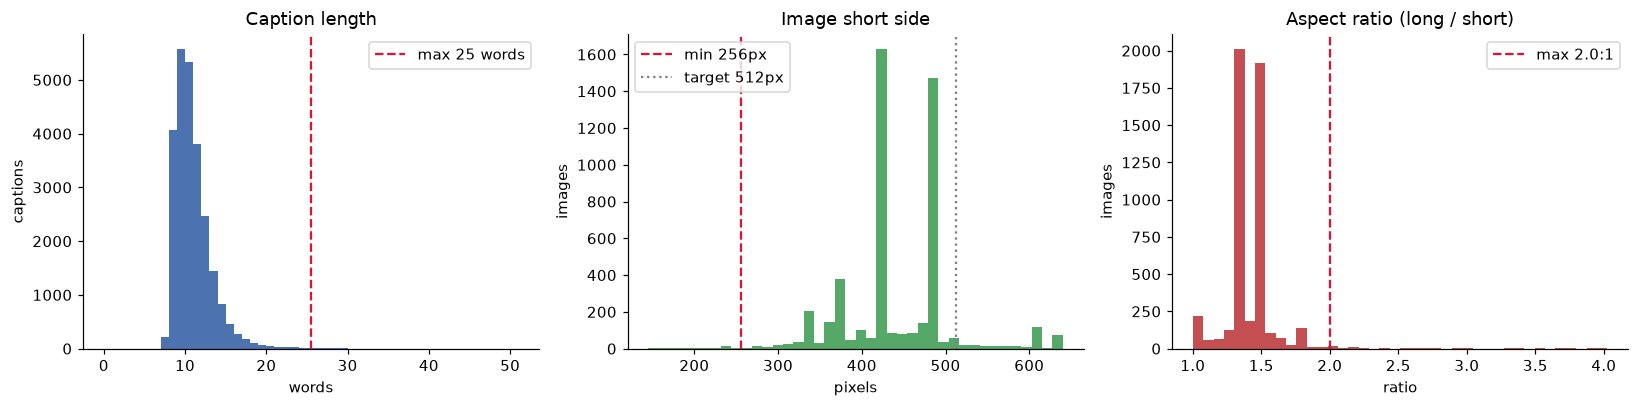

Caption words : mean 10.4, median 10, min 7, max 50
Short side    : min 145px, median 427px; 93% of images are smaller than 512px and will be upscaled slightly
Aspect ratio  : median 1.39; 53 images above 2.0:1


In [4]:
cap_words = captions.caption_raw.str.split().str.len()
short_side = images[["width", "height"]].min(axis=1)
aspect = images[["width", "height"]].max(axis=1) / short_side

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
axes[0].hist(cap_words, bins=range(0, cap_words.max() + 2), color="#4C72B0")
axes[0].axvline(MAX_WORDS + 0.5, color="crimson", ls="--", label=f"max {MAX_WORDS} words")
axes[0].set(title="Caption length", xlabel="words", ylabel="captions"); axes[0].legend()
axes[1].hist(short_side, bins=40, color="#55A868")
axes[1].axvline(MIN_SIDE, color="crimson", ls="--", label=f"min {MIN_SIDE}px")
axes[1].axvline(IMAGE_SIZE, color="gray", ls=":", label=f"target {IMAGE_SIZE}px")
axes[1].set(title="Image short side", xlabel="pixels", ylabel="images"); axes[1].legend()
axes[2].hist(aspect, bins=40, color="#C44E52")
axes[2].axvline(MAX_ASPECT, color="crimson", ls="--", label=f"max {MAX_ASPECT}:1")
axes[2].set(title="Aspect ratio (long / short)", xlabel="ratio", ylabel="images"); axes[2].legend()
fig.tight_layout(); fig.savefig(FIG_DIR / "01_raw_distributions.png", bbox_inches="tight"); plt.show()

print(f"Caption words : mean {cap_words.mean():.1f}, median {cap_words.median():.0f}, min {cap_words.min()}, max {cap_words.max()}")
print(f"Short side    : min {short_side.min()}px, median {short_side.median():.0f}px; "
      f"{(short_side < IMAGE_SIZE).mean():.0%} of images are smaller than {IMAGE_SIZE}px and will be upscaled slightly")
print(f"Aspect ratio  : median {aspect.median():.2f}; {(aspect > MAX_ASPECT).sum()} images above {MAX_ASPECT}:1")

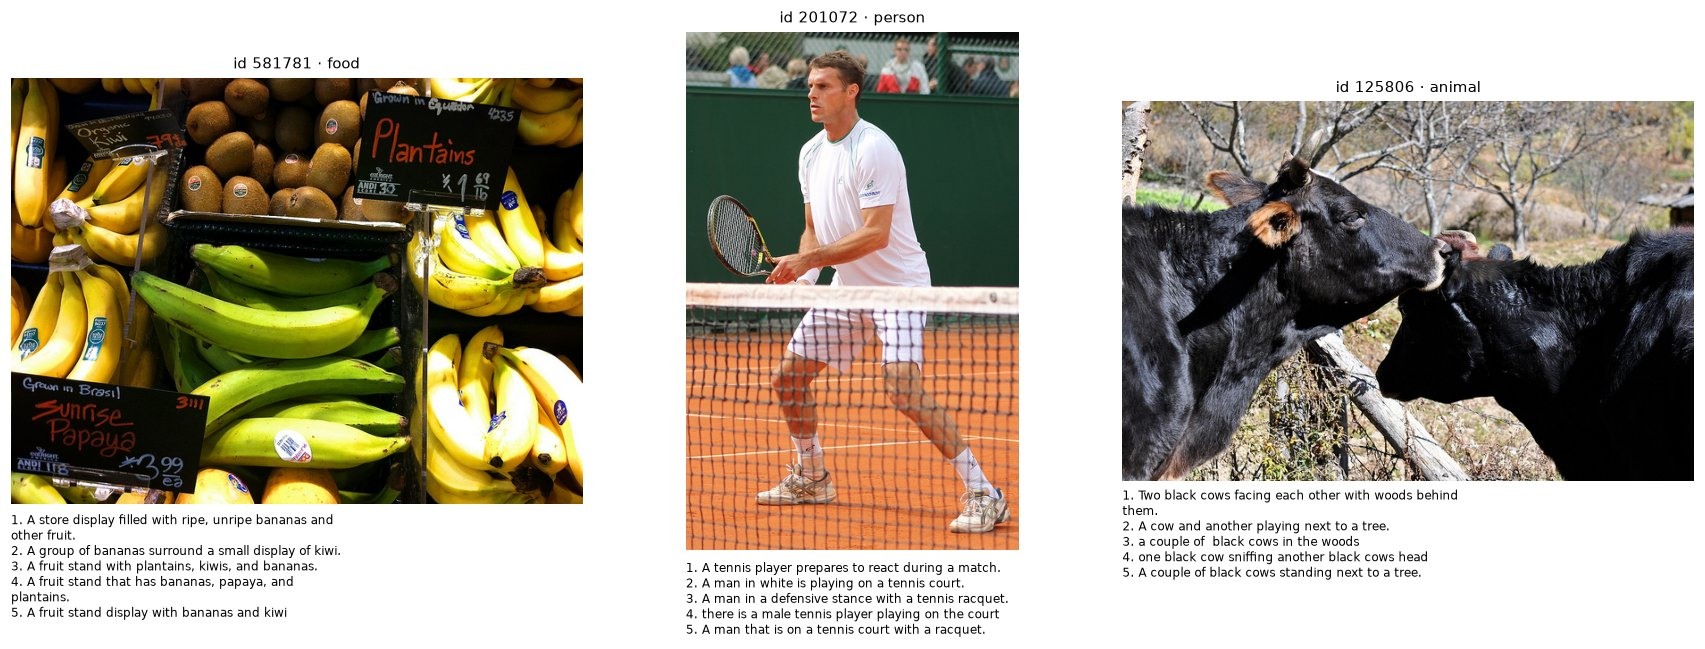

In [5]:
def show_with_captions(image_ids, caption_col="caption_raw", df=None, ncols=3):
    df = captions if df is None else df
    fig, axes = plt.subplots(1, ncols, figsize=(5.2 * ncols, 6))
    for ax, iid in zip(np.atleast_1d(axes), image_ids):
        row = images.loc[images.image_id == iid].iloc[0]
        ax.imshow(Image.open(IMG_DIR / row.file_name)); ax.axis("off")
        caps = df.loc[df.image_id == iid, caption_col].tolist()
        text = "\n".join(textwrap.fill(f"{i + 1}. {c.strip()}", 55) for i, c in enumerate(caps))
        ax.set_title(f"id {iid} · {row.supercategory}", fontsize=10)
        ax.text(0, -0.02, text, transform=ax.transAxes, va="top", fontsize=8)
    fig.tight_layout(); plt.show()

show_with_captions(np.random.default_rng(SEED).choice(images.image_id, 3, replace=False))

## 3. Caption cleaning

### 3.1 Audit the raw captions
Before changing anything, count how often each problem actually occurs, so every cleaning rule is backed by data.

In [6]:
raw = captions.caption_raw
issues = {
    "Leading / trailing whitespace": raw != raw.str.strip(),
    "Embedded newline or tab":       raw.str.contains(r"[\n\t]"),
    "Repeated spaces":               raw.str.contains(r" {2,}"),
    "Space before punctuation":      raw.str.contains(r" [.,!?;:]"),
    "Repeated punctuation":          raw.str.contains(r"[.,!?]{2,}"),
    "Written in ALL CAPS":           raw.str.strip().str.isupper(),
    "HTML tags / entities":          raw.str.contains(r"<[^>]+>|&[a-z]+;"),
    "Other special characters":      raw.str.contains(r"[^A-Za-z0-9\s.,'!?&\-]"),
    "Any uppercase letter":          raw.str.contains(r"[A-Z]"),
}
issue_counts = pd.DataFrame({"captions": {k: int(v.sum()) for k, v in issues.items()}})
issue_counts["share"] = (issue_counts.captions / len(raw)).map("{:.2%}".format)
issue_counts

,captions,share
Leading / trailing whitespace,3541,14.16%
Embedded newline or tab,83,0.33%
Repeated spaces,380,1.52%
Space before punctuation,37,0.15%
Repeated punctuation,20,0.08%
Written in ALL CAPS,174,0.70%
HTML tags / entities,0,0.00%
Other special characters,101,0.40%
Any uppercase letter,21332,85.28%


In [7]:
print("Examples with special characters:")
for c in raw[issues["Other special characters"]].head(8):
    print("  ", repr(c))

Examples with special characters:
   'The bathroom features a vanity sink and tub/shower combination.'
   'The white and yellow clock with a red roof reads 11:44.'
   'Bathroom with orange shower and mirror/cabinet curtains '
   'A black motorcycle parked at a building that says "500".'
   'A youth on a toilet taking a "selfie" in a mirror.'
   'A toilet from above; flanked by a toilet brush and a small trash can.  '
   'A game at an outdoor fair called "Ball In The Bog"'
   'Traffic lights being repaired and/or replaced by a man.'


### 3.2 Cleaning rules
`clean_caption` applies these steps in order:

1. **Repair Unicode** with `ftfy` (mojibake, curly quotes) and NFKC-normalize.
2. **Strip HTML**: unescape entities, remove tags.
3. **Lowercase.** CLIP's tokenizer lowercases anyway, and this makes duplicates match.
4. **Map `;` and `:` to commas** so clause boundaries survive.
5. **Remove any other character** outside letters, digits, spaces and `. , ' ! ? & -`. This covers newlines, `#`, brackets and quotes.
6. **Fix punctuation spacing**: collapse repeated marks, remove the space before a mark, add one after it.
7. **Collapse whitespace**, then strip leading junk and trailing periods and commas.

The original text stays in `caption_raw`, so the cleaning can always be audited or reverted.

In [8]:
_DISALLOWED = re.compile(r"[^a-z0-9 .,'!?&\-]")

def clean_caption(text: str) -> str:
    t = unicodedata.normalize("NFKC", fix_text(str(text)))
    t = re.sub(r"<[^>]+>", " ", html.unescape(t))
    t = t.lower()
    t = re.sub(r"[;:]", ",", t)
    t = _DISALLOWED.sub(" ", t)
    t = re.sub(r"([.,!?])\1+", r"\1", t)          # "..", ",,"  -> single mark
    t = re.sub(r"\s+([.,!?])", r"\1", t)          # "word ."    -> "word."
    t = re.sub(r"([.,!?])(?=[a-z])", r"\1 ", t)   # "word,next" -> "word, next"
    t = re.sub(r"\s+", " ", t).strip()
    t = re.sub(r"^[^a-z0-9]+", "", t)
    return t.rstrip(" .,")

# Unit checks on real COCO captions (plus one synthetic HTML case)
checks = {
    "A dog sitting on top of stairs.] with a red bow tie.": "a dog sitting on top of stairs. with a red bow tie",
    "Two pizza pies sitting atop a stove getting ready to be cut\n.": "two pizza pies sitting atop a stove getting ready to be cut",
    "The #41 bus parked at the curb waiting for passengers to board": "the 41 bus parked at the curb waiting for passengers to board",
    "A  small bus traveling down a street.": "a small bus traveling down a street",
    "A BENCH IS SEATED ON THE GRASS": "a bench is seated on the grass",
    "a man in western gear , who is looking back..": "a man in western gear, who is looking back",
    "Bowls with food; Big bowl has patties": "bowls with food, big bowl has patties",
    "Fish &amp; chips <b>on</b> a plate": "fish & chips on a plate",
}
for src, expected in checks.items():
    got = clean_caption(src)
    assert got == expected, f"{src!r} -> {got!r} (expected {expected!r})"
print(f"All {len(checks)} cleaning checks passed.")

All 8 cleaning checks passed.


In [9]:
captions["caption"] = captions.caption_raw.map(clean_caption)
changed = captions[captions.caption != captions.caption_raw]
print(f"Captions altered by cleaning: {len(changed):,} of {len(captions):,} ({len(changed) / len(captions):.1%})")

# Show the most interesting changes: those beyond simple lowercasing/trailing-period removal
trivial = changed.caption_raw.str.lower().str.strip().str.rstrip(".").str.strip() == changed.caption
pd.set_option("display.max_colwidth", 90)
changed.loc[~trivial, ["caption_raw", "caption"]].sample(10, random_state=SEED)

Captions altered by cleaning: 22,435 of 25,014 (89.7%)


,caption_raw,caption
16953,A person in a snow sporting event is going rapidly down this show chute-type course a...,a person in a snow sporting event is going rapidly down this show chute-type course as...
2446,a person jumping in the air on a motorcycle,a person jumping in the air on a motorcycle
19215,A couple of people standing on top of a snow covered slope.,a couple of people standing on top of a snow covered slope
11658,"A man with a beard wearing a white suit standing near a garden,",a man with a beard wearing a white suit standing near a garden
8565,several cows grazing in a grassy open field.,several cows grazing in a grassy open field
10551,a very ugly cow with long horns staring,a very ugly cow with long horns staring
9364,A deck with a chair and a table with umbrella on it.,a deck with a chair and a table with umbrella on it
5936,Street signs from the corner of 8th ave. and 22 3/4 st.,street signs from the corner of 8th ave. and 22 3 4 st
22440,"A child holding a pink toy cell phone with ""Princess Aurora"" inside it.",a child holding a pink toy cell phone with princess aurora inside it
1723,a river.A group of people with life jacket rowing a long boat in,a river. a group of people with life jacket rowing a long boat in


### 3.3 Caption filters
COCO captions are written to a guideline, so all of them already have at least 7 words. The filters that
matter are at the long end and for duplicates:

* **Empty / fewer than 5 words**: a safety net that removes nothing on COCO, but protects re-use on other data.
* **More than 25 words**: rare run-on descriptions, far from the prompt style we will generate with.
* **Over 77 CLIP tokens**: the text encoder would silently truncate them.
* **Duplicate caption for the same image**: two annotators wrote the same sentence.

In [10]:
tokenizer = CLIPTokenizer.from_pretrained(CLIP_TOKENIZER_ID)
captions["n_words"] = captions.caption.str.split().str.len().fillna(0).astype(int)
captions["n_clip_tokens"] = [len(ids) for ids in tokenizer(captions.caption.tolist())["input_ids"]]

filter_log = []
def log_step(stage, unit, before, after):
    filter_log.append({"stage": stage, "unit": unit, "before": before, "removed": before - after, "after": after})

caption_filters = [
    ("Empty after cleaning",                      lambda d: d.caption.str.len() > 0),
    (f"Fewer than {MIN_WORDS} words",             lambda d: d.n_words >= MIN_WORDS),
    (f"More than {MAX_WORDS} words",              lambda d: d.n_words <= MAX_WORDS),
    (f"Over {MAX_CLIP_TOKENS} CLIP tokens",       lambda d: d.n_clip_tokens <= MAX_CLIP_TOKENS),
    ("Duplicate caption for the same image",      lambda d: ~d.duplicated(["image_id", "caption"])),
]
valid_caps, dropped = captions.copy(), {}
for stage, keep in caption_filters:
    mask = keep(valid_caps)
    dropped[stage] = valid_caps[~mask]
    log_step(stage, "caption", len(valid_caps), int(mask.sum()))
    valid_caps = valid_caps[mask]

print(f"CLIP tokens per caption: max {captions.n_clip_tokens.max()}, mean {captions.n_clip_tokens.mean():.1f}")
pd.DataFrame(filter_log)

CLIP tokens per caption: max 57, mean 12.8


,stage,unit,before,removed,after
0,Empty after cleaning,caption,25014,0,25014
1,Fewer than 5 words,caption,25014,0,25014
2,More than 25 words,caption,25014,27,24987
3,Over 77 CLIP tokens,caption,24987,0,24987
4,Duplicate caption for the same image,caption,24987,14,24973


In [11]:
for stage in (f"More than {MAX_WORDS} words", "Duplicate caption for the same image"):
    print(f"--- {stage} (examples)")
    for c in dropped[stage].caption.head(3):
        print("  ", textwrap.shorten(c, 140))

--- More than 25 words (examples)
   two almost identical photos with some minor cropping show two young girls standing on the coast with people in the water in the [...]
   a white slope covers the background, while the foreground features a grassy slope with several rams grazing and one measly and [...]
   what appears to be a beach-side eatery has an outdoor area with a metal railing and high stools, the whole of which rests on a tilted [...]
--- Duplicate caption for the same image (examples)
   a man blowing out candles on a cake
   a man blowing out candles on a cake
   a man walking down a street smoking a cigarette


Some identical captions describe **different** images (e.g. *"a man riding a skateboard"*).
They're valid, so we keep them, but we flag them and avoid choosing them as an image's primary caption.
A caption that matches several images would make the retrieval checks in notebook 02 ambiguous.

In [12]:
valid_caps["dup_across_images"] = valid_caps.caption.duplicated(keep=False)
print(f"Captions shared with another image: {valid_caps.dup_across_images.sum():,}")
valid_caps[valid_caps.dup_across_images].caption.value_counts().head(8)

Captions shared with another image: 369


caption
a large long train on a steel track                         11
a man holding a tennis racquet on a tennis court            10
a person riding a surf board on a wave                      10
a man riding a wave on top of a surfboard                    8
a public transit bus on a city street                        7
a man flying through the air while riding a skateboard       7
the big ben clock tower towering over the city of london     6
a man standing on a tennis court holding a racquet           6
Name: count, dtype: int64

## 4. Image validation
Open every file to make sure it decodes, record its colour mode and real size, then filter:

* **Unreadable / corrupt** files.
* **Short side < 256 px**: these would need more than 2× upscaling to reach 512 px.
* **Aspect ratio > 2:1**: a square center-crop would keep less than half the scene, so the caption may describe things that are no longer visible.
* **No captions left** after cleaning.

Grayscale images aren't dropped. They are converted to 3-channel RGB in step 6.

In [13]:
def inspect_image(file_name):
    try:
        with Image.open(IMG_DIR / file_name) as im:
            im.verify()                      # integrity check (header + structure)
        with Image.open(IMG_DIR / file_name) as im:
            im.load()                        # full decode
            return {"readable": True, "mode": im.mode, "pil_w": im.width, "pil_h": im.height}
    except Exception as exc:                 # noqa: BLE001 - any failure means "unusable"
        return {"readable": False, "mode": None, "pil_w": None, "pil_h": None, "error": str(exc)}

with ThreadPoolExecutor(max_workers=8) as pool:
    info = list(tqdm(pool.map(inspect_image, images.file_name), total=len(images), desc="Inspecting images"))
images = pd.concat([images, pd.DataFrame(info)], axis=1)

size_mismatch = images.readable & ((images.pil_w != images.width) | (images.pil_h != images.height))
print(f"Unreadable files            : {(~images.readable).sum()}")
print(f"Size differs from annotation: {size_mismatch.sum()}")
print("Colour modes                :", images["mode"].value_counts(dropna=False).to_dict())

Inspecting images:   0%|          | 0/5000 [00:00<?, ?it/s]

Inspecting images:   8%|▊         | 398/5000 [00:00<00:01, 3922.27it/s]

Inspecting images:  16%|█▌        | 809/5000 [00:00<00:01, 4028.62it/s]

Inspecting images:  24%|██▍       | 1212/5000 [00:00<00:00, 3946.15it/s]

Inspecting images:  32%|███▏      | 1618/5000 [00:00<00:00, 3977.11it/s]

Inspecting images:  40%|████      | 2025/5000 [00:00<00:00, 4007.06it/s]

... (5 outputs left out)

Inspecting images:  89%|████████▉ | 4473/5000 [00:01<00:00, 4074.11it/s]

Inspecting images:  98%|█████████▊| 4882/5000 [00:01<00:00, 4076.91it/s]

Inspecting images: 100%|██████████| 5000/5000 [00:01<00:00, 4026.00it/s]

Unreadable files            : 0
Size differs from annotation: 0
Colour modes                : {'RGB': 4990, 'L': 10}


In [14]:
images["short_side"] = images[["width", "height"]].min(axis=1)
images["aspect"] = images[["width", "height"]].max(axis=1) / images.short_side
images["is_grayscale"] = images["mode"] != "RGB"

image_filters = [
    ("Unreadable / corrupt file",          lambda d: d.readable),
    (f"Short side < {MIN_SIDE}px",         lambda d: d.short_side >= MIN_SIDE),
    (f"Aspect ratio > {MAX_ASPECT}:1",     lambda d: d.aspect <= MAX_ASPECT),
    ("No valid captions left",             lambda d: d.image_id.isin(valid_caps.image_id)),
]
eligible, dropped_imgs = images.copy(), {}
for stage, keep in image_filters:
    mask = keep(eligible)
    dropped_imgs[stage] = eligible[~mask]
    log_step(stage, "image", len(eligible), int(mask.sum()))
    eligible = eligible[mask]

valid_caps = valid_caps[valid_caps.image_id.isin(eligible.image_id)]
print(f"Eligible images: {len(eligible):,} · their valid captions: {len(valid_caps):,}")
pd.DataFrame([r for r in filter_log if r["unit"] == "image"])

Eligible images: 4,926 · their valid captions: 24,602


,stage,unit,before,removed,after
0,Unreadable / corrupt file,image,5000,0,5000
1,Short side < 256px,image,5000,42,4958
2,Aspect ratio > 2.0:1,image,4958,32,4926
3,No valid captions left,image,4926,0,4926


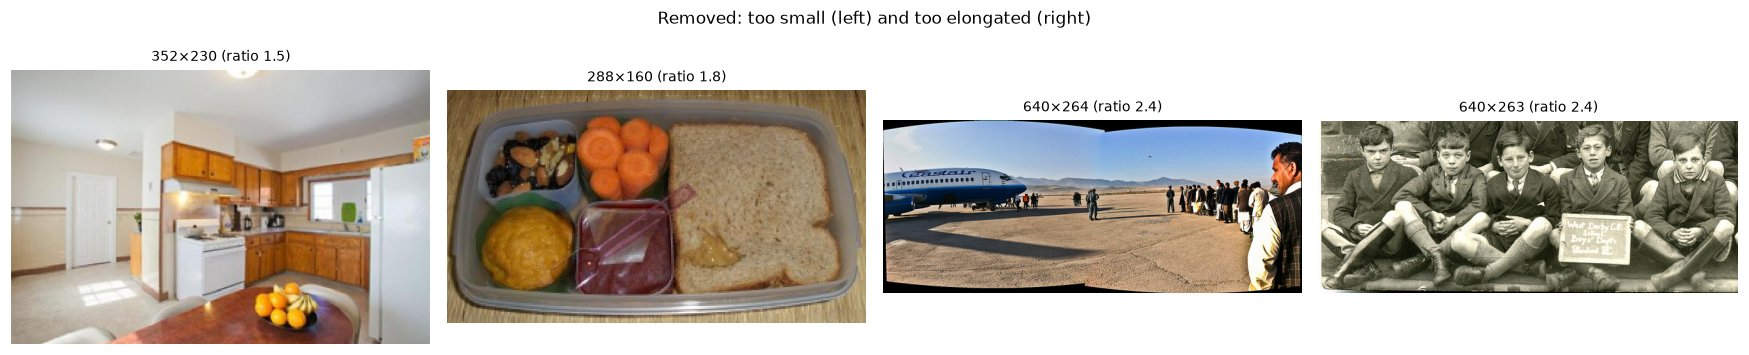

In [15]:
# What the image filters removed
examples = pd.concat([dropped_imgs[f"Short side < {MIN_SIDE}px"].head(2),
                      dropped_imgs[f"Aspect ratio > {MAX_ASPECT}:1"].sort_values("aspect").tail(2)])
fig, axes = plt.subplots(1, len(examples), figsize=(4 * len(examples), 3.4))
for ax, row in zip(axes, examples.itertuples()):
    ax.imshow(Image.open(IMG_DIR / row.file_name)); ax.axis("off")
    ax.set_title(f"{row.width}×{row.height} (ratio {row.aspect:.1f})", fontsize=9)
fig.suptitle("Removed: too small (left) and too elongated (right)", fontsize=11)
fig.tight_layout(); plt.show()

## 5. Curated subset, primary captions and splits

* **Subset:** a seeded random sample of `N_IMAGES` eligible images. The bar chart below checks that it keeps the dataset's category mix.
* **Primary caption:** each image gets one caption that forms its *pair*. It is chosen at random (seeded), but captions unique to that image are preferred. All of the image's other valid captions are kept in `captions.parquet` for multi-reference evaluation.
* **Splits:** 80 / 10 / 10 **by image**, so no image (or any of its captions) appears in two splits.

In [16]:
# A fresh, seeded generator: the split never depends on which cells ran before this one
rng = np.random.default_rng(SEED)
subset = eligible.sample(n=min(N_IMAGES, len(eligible)), random_state=SEED).reset_index(drop=True)

# Split by image
perm = rng.permutation(len(subset))
n_train = round(SPLIT_FRACS["train"] * len(subset))
n_val = round(SPLIT_FRACS["val"] * len(subset))
split = np.empty(len(subset), dtype=object)
split[perm[:n_train]] = "train"
split[perm[n_train:n_train + n_val]] = "val"
split[perm[n_train + n_val:]] = "test"
subset["split"] = split

# Primary caption: unique-to-image captions first, then a seeded random tie-break
sub_caps = valid_caps[valid_caps.image_id.isin(subset.image_id)].copy()
sub_caps["_rand"] = rng.random(len(sub_caps))
primary_ids = (sub_caps.sort_values(["image_id", "dup_across_images", "_rand"])
                       .drop_duplicates("image_id").caption_id)
sub_caps["is_primary"] = sub_caps.caption_id.isin(primary_ids)
sub_caps = sub_caps.drop(columns="_rand").merge(subset[["image_id", "split"]], on="image_id")

print(f"Subset images  : {len(subset):,}")
print(f"Pairs          : {sub_caps.is_primary.sum():,} (one primary caption per image)")
print(f"All captions   : {len(sub_caps):,} ({len(sub_caps) / len(subset):.2f} per image)")
print("Split sizes    :", subset.split.value_counts().reindex(SPLIT_FRACS).to_dict())

Subset images  : 4,000
Pairs          : 4,000 (one primary caption per image)
All captions   : 19,977 (4.99 per image)
Split sizes    : {'train': 3200, 'val': 400, 'test': 400}


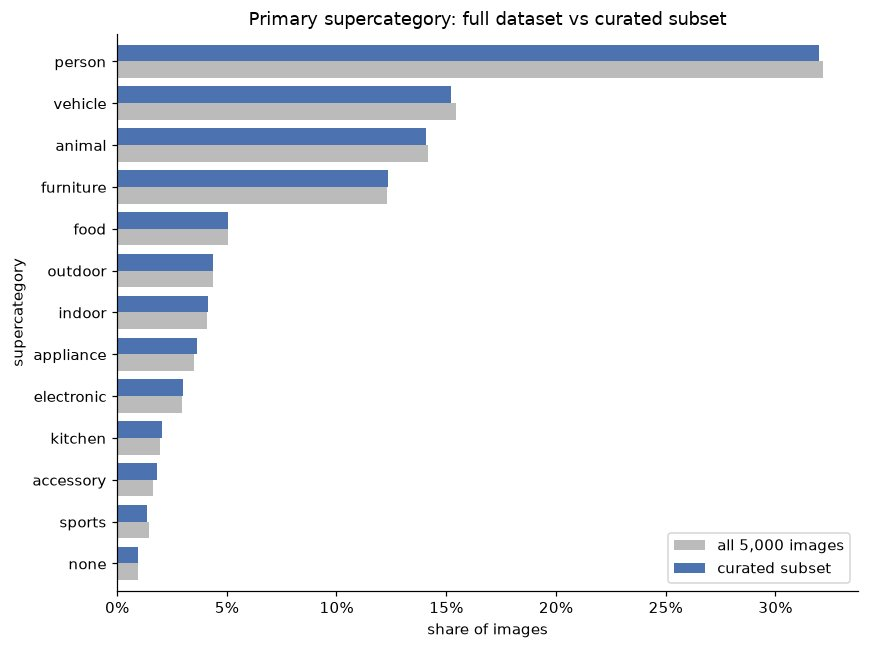

Largest share difference: 0.26%


In [17]:
dist = pd.DataFrame({
    "all 5,000 images": images.supercategory.value_counts(normalize=True),
    "curated subset": subset.supercategory.value_counts(normalize=True),
}).fillna(0).sort_values("all 5,000 images")
ax = dist.plot.barh(figsize=(8, 6), color=["#BBBBBB", "#4C72B0"], width=0.8)
ax.set(xlabel="share of images", title="Primary supercategory: full dataset vs curated subset")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:.0%}"))
plt.tight_layout(); plt.savefig(FIG_DIR / "01_subset_categories.png", bbox_inches="tight"); plt.show()
print(f"Largest share difference: {(dist.iloc[:, 0] - dist.iloc[:, 1]).abs().max():.2%}")

## 6. Image preprocessing

### 6.1 Resize and center-crop to 512×512
Each image is converted to **RGB** (which fixes the grayscale files), its **short side resized to 512 px**
with Lanczos resampling, and a **512×512 center crop** taken. This keeps the aspect ratio undistorted,
which a plain resize would not. Results are saved as high-quality JPEGs (q=95) in `data/processed/images_512/`.

In [18]:
def resize_center_crop(img: Image.Image, size: int = IMAGE_SIZE) -> Image.Image:
    img = img.convert("RGB")
    w, h = img.size
    scale = size / min(w, h)
    new_w, new_h = max(size, round(w * scale)), max(size, round(h * scale))
    img = img.resize((new_w, new_h), Image.Resampling.LANCZOS)
    left, top = (new_w - size) // 2, (new_h - size) // 2
    return img.crop((left, top, left + size, top + size))

def process_one(row):
    dst = OUT_IMG_DIR / f"{row.image_id:012d}.jpg"
    with Image.open(IMG_DIR / row.file_name) as im:
        resize_center_crop(im).save(dst, format="JPEG", quality=95)
    return dst.relative_to(ROOT).as_posix()

with ThreadPoolExecutor(max_workers=8) as pool:
    subset["image_path"] = list(tqdm(pool.map(process_one, subset.itertuples()), total=len(subset),
                                     desc="Resizing to 512x512"))

kept_area = 1 / subset.aspect
print(f"Processed {len(subset):,} images -> {OUT_IMG_DIR.relative_to(ROOT)}")
print(f"Upscaled (short side < {IMAGE_SIZE}px): {(subset.short_side < IMAGE_SIZE).sum():,} · "
      f"grayscale converted to RGB: {subset.is_grayscale.sum()}")
print(f"Share of the original image kept by the square crop: mean {kept_area.mean():.0%}, worst {kept_area.min():.0%}")

Resizing to 512x512:   0%|          | 0/4000 [00:00<?, ?it/s]

Resizing to 512x512:   2%|▏         | 96/4000 [00:00<00:04, 959.76it/s]

Resizing to 512x512:   6%|▌         | 223/4000 [00:00<00:03, 1134.83it/s]

Resizing to 512x512:   9%|▉         | 356/4000 [00:00<00:03, 1211.22it/s]

Resizing to 512x512:  12%|█▏        | 484/4000 [00:00<00:02, 1227.93it/s]

Resizing to 512x512:  15%|█▌        | 615/4000 [00:00<00:02, 1234.04it/s]

... (25 outputs left out)

Resizing to 512x512:  95%|█████████▌| 3805/4000 [00:03<00:00, 1189.98it/s]

Resizing to 512x512:  98%|█████████▊| 3929/4000 [00:03<00:00, 1201.90it/s]

Resizing to 512x512: 100%|██████████| 4000/4000 [00:03<00:00, 1195.42it/s]

Processed 4,000 images -> data/processed/images_512
Upscaled (short side < 512px): 3,718 · grayscale converted to RGB: 9
Share of the original image kept by the square crop: mean 72%, worst 50%


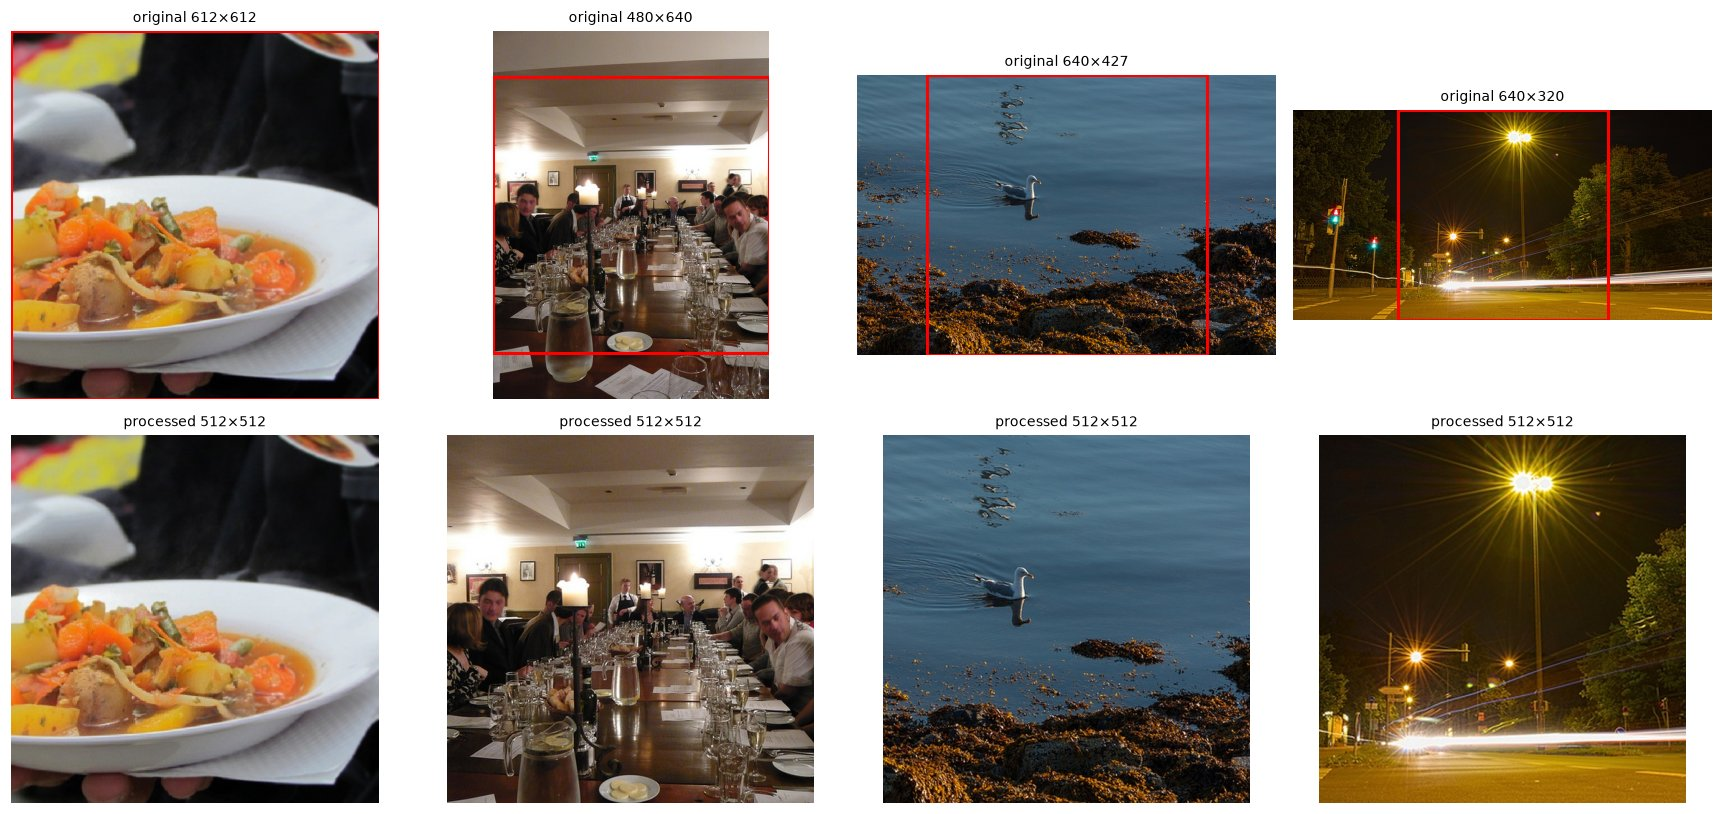

In [19]:
# Before / after: the red box marks the area kept by the center crop
demo = subset.sort_values("aspect").iloc[np.linspace(0, len(subset) - 1, 4).astype(int)]
fig, axes = plt.subplots(2, 4, figsize=(16, 7.5))
for col, row in enumerate(demo.itertuples()):
    orig = Image.open(IMG_DIR / row.file_name)
    s = min(orig.size)
    axes[0, col].imshow(orig)
    axes[0, col].add_patch(Rectangle(((orig.width - s) / 2, (orig.height - s) / 2), s, s,
                                     fill=False, ec="red", lw=2))
    axes[0, col].set_title(f"original {orig.width}×{orig.height}", fontsize=9)
    axes[1, col].imshow(Image.open(ROOT / row.image_path))
    axes[1, col].set_title("processed 512×512", fontsize=9)
for ax in axes.flat:
    ax.axis("off")
fig.tight_layout(); fig.savefig(FIG_DIR / "01_resize_crop.png", bbox_inches="tight"); plt.show()

### 6.2 Normalization
Stable Diffusion's VAE expects pixels in **`[-1, 1]`**, so `ToTensor()` (which gives `[0, 1]`) is followed
by `Normalize(mean=0.5, std=0.5)`. Storing normalized float tensors would take about 12 GB for 4,000 images,
so the normalization runs on the fly in a `Dataset`. Later milestones can reuse that `Dataset` as is.

In [20]:
sd_transform = T.Compose([T.ToTensor(), T.Normalize([0.5] * 3, [0.5] * 3)])   # [0,1] -> [-1,1]

class CocoPairs(Dataset):
    # (image tensor in [-1, 1], caption) pairs from pairs.parquet
    def __init__(self, pairs: pd.DataFrame, split: str | None = None, transform=sd_transform):
        self.df = (pairs if split is None else pairs[pairs.split == split]).reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, i):
        row = self.df.iloc[i]
        with Image.open(ROOT / row.image_path) as im:
            return self.transform(im.convert("RGB")), row.caption

pairs = (subset.merge(sub_caps[sub_caps.is_primary][["image_id", "caption_id", "caption", "caption_raw",
                                                     "n_words", "n_clip_tokens"]], on="image_id"))
batch_imgs, batch_caps = next(iter(DataLoader(CocoPairs(pairs, "train"), batch_size=8, shuffle=True)))
print(f"Batch tensor : {tuple(batch_imgs.shape)}  dtype {batch_imgs.dtype}")
print(f"Value range  : [{batch_imgs.min():.3f}, {batch_imgs.max():.3f}]  mean {batch_imgs.mean():.3f}")
assert batch_imgs.shape[1:] == (3, IMAGE_SIZE, IMAGE_SIZE) and batch_imgs.min() >= -1 and batch_imgs.max() <= 1
print("First caption:", batch_caps[0])

Batch tensor : (8, 3, 512, 512)  dtype torch.float32
Value range  : [-1.000, 1.000]  mean -0.170
First caption: two giraffes are in the wilderness, possibly eating


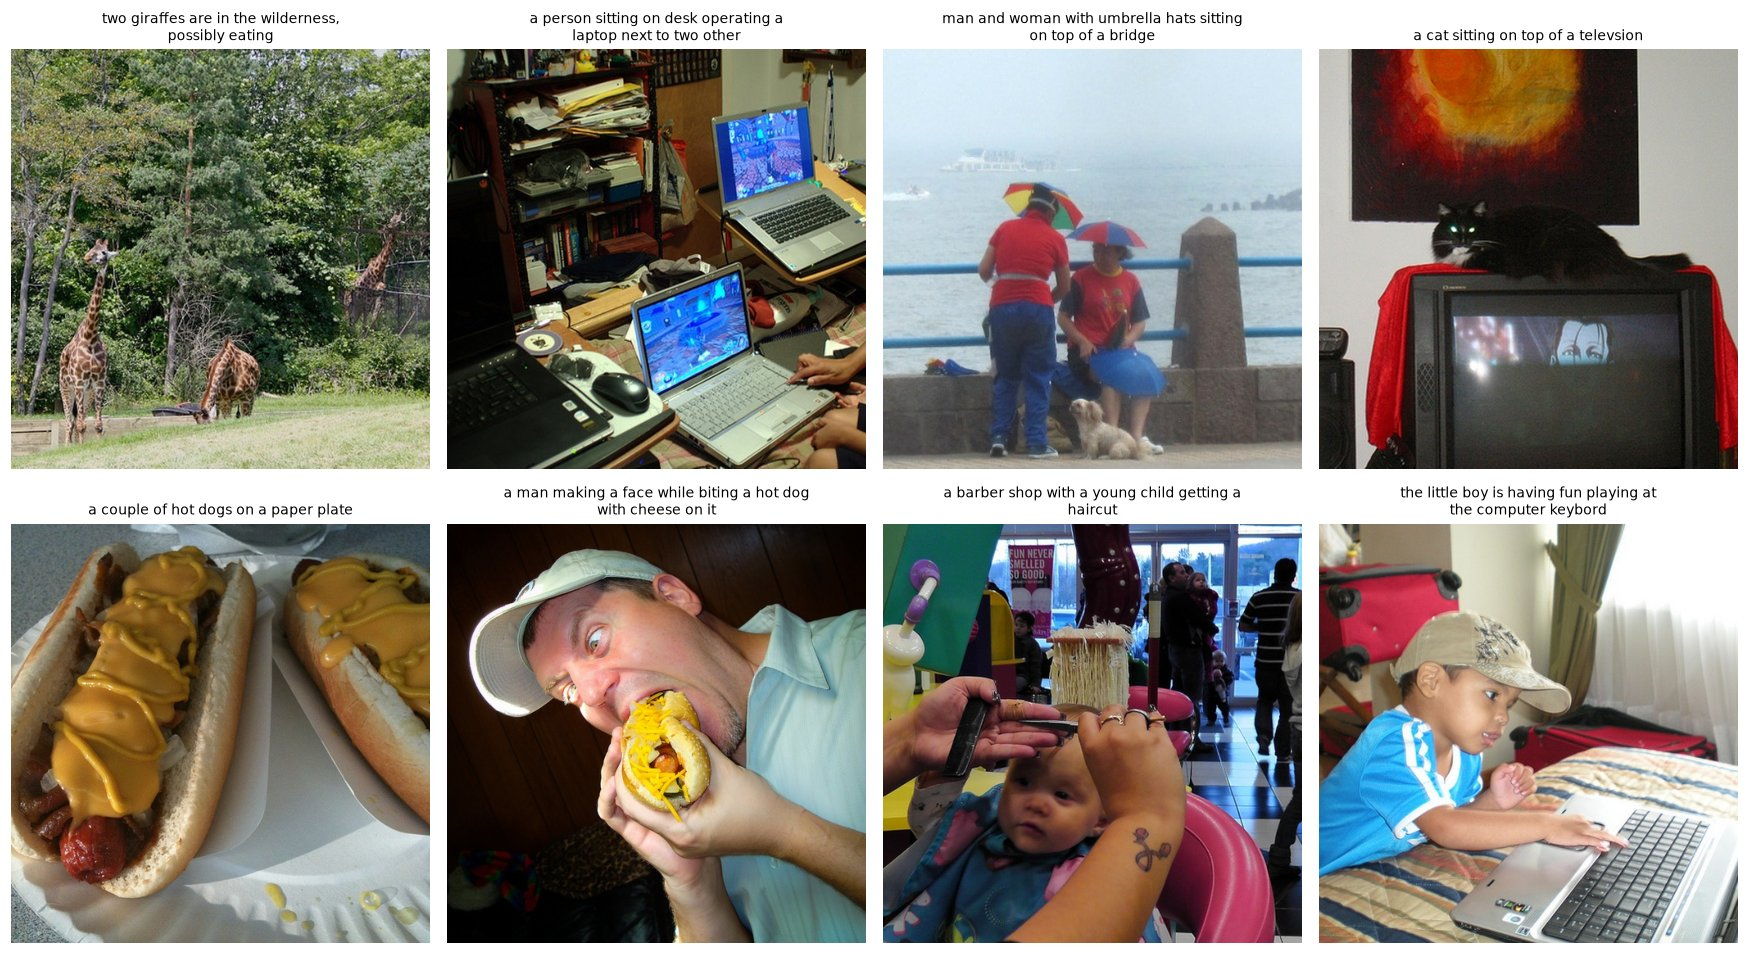

In [21]:
# Sanity check: undo the normalization and display the batch with its captions
fig, axes = plt.subplots(2, 4, figsize=(16, 9))
for ax, img, cap in zip(axes.flat, batch_imgs, batch_caps):
    ax.imshow(((img + 1) / 2).permute(1, 2, 0).clamp(0, 1).numpy()); ax.axis("off")
    ax.set_title(textwrap.fill(cap, 42), fontsize=9)
fig.tight_layout(); fig.savefig(FIG_DIR / "01_sample_pairs.png", bbox_inches="tight"); plt.show()

## 7. Save the processed dataset

In [22]:
pair_cols = ["image_id", "caption_id", "caption", "caption_raw", "split", "image_path", "file_name",
             "width", "height", "supercategory", "categories", "is_grayscale", "n_words", "n_clip_tokens"]
pairs = pairs[pair_cols].sort_values("image_id").reset_index(drop=True)
all_caps = (sub_caps[["caption_id", "image_id", "caption", "caption_raw", "split", "is_primary",
                      "dup_across_images", "n_words", "n_clip_tokens"]]
              .sort_values(["image_id", "caption_id"]).reset_index(drop=True))

pairs.to_parquet(PROC_DIR / "pairs.parquet", index=False)
all_caps.to_parquet(PROC_DIR / "captions.parquet", index=False)

report = {
    "created_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    "source": "COCO 2017 val (captions_val2017.json, instances_val2017.json)",
    "config": {"seed": SEED, "n_images": N_IMAGES, "image_size": IMAGE_SIZE, "min_side": MIN_SIDE,
               "max_aspect": MAX_ASPECT, "min_words": MIN_WORDS, "max_words": MAX_WORDS,
               "max_clip_tokens": MAX_CLIP_TOKENS, "split_fracs": SPLIT_FRACS,
               "clip_tokenizer": CLIP_TOKENIZER_ID},
    "raw": {"images": len(images), "captions": len(captions)},
    "caption_issues": issue_counts.captions.to_dict(),
    "captions_altered_by_cleaning": len(changed),
    "filter_log": filter_log,
    "eligible": {"images": len(eligible), "captions": len(valid_caps)},
    "final": {"pairs": len(pairs), "captions": len(all_caps),
              "splits": pairs.split.value_counts().to_dict(),
              "grayscale_converted": int(pairs.is_grayscale.sum())},
    "versions": {"python": sys.version.split()[0], "torch": torch.__version__,
                 "torchvision": torchvision.__version__, "transformers": transformers.__version__},
}
(PROC_DIR / "cleaning_report.json").write_text(json.dumps(report, indent=2, default=int))

for p in sorted(PROC_DIR.iterdir()):
    size = sum(f.stat().st_size for f in p.glob("*")) if p.is_dir() else p.stat().st_size
    print(f"{p.relative_to(ROOT).as_posix():45s} {size / 1e6:8.1f} MB")
pairs.head()

data/processed/captions.parquet                    1.4 MB
data/processed/cleaning_report.json                0.0 MB
data/processed/images_512                        456.9 MB
data/processed/pairs.parquet                       0.4 MB


,image_id,caption_id,caption,caption_raw,split,image_path,file_name,width,height,supercategory,categories,is_grayscale,n_words,n_clip_tokens
0,632,305425,this room has a bed with blue sheets and a large bookcase,This room has a bed with blue sheets and a large bookcase,train,data/processed/images_512/000000000632.jpg,000000000632.jpg,640,483,furniture,"[bed, book, chair, potted plant]",False,12,15
1,724,399297,a stop sign that is hanging upside down,A stop sign that is hanging upside down.,train,data/processed/images_512/000000000724.jpg,000000000724.jpg,375,500,outdoor,"[car, stop sign, truck]",False,8,10
2,776,639641,three stuffed animals are sitting on a bed,Three stuffed animals are sitting on a bed.,train,data/processed/images_512/000000000776.jpg,000000000776.jpg,428,640,indoor,"[bed, teddy bear]",False,8,10
3,785,502082,a young woman is skiing down the mountain slope,A young woman is skiing down the mountain slope.,train,data/processed/images_512/000000000785.jpg,000000000785.jpg,640,425,person,"[person, skis]",False,9,11
4,802,624271,a white oven and a white refrigerator are in the kitchen,A white oven and a white refrigerator are in the kitchen.,train,data/processed/images_512/000000000802.jpg,000000000802.jpg,424,640,appliance,"[oven, refrigerator]",False,11,13


### Final validation

In [23]:
reloaded = pd.read_parquet(PROC_DIR / "pairs.parquet")
caps_reloaded = pd.read_parquet(PROC_DIR / "captions.parquet")

assert 1000 <= len(reloaded) <= 5000, "milestone requires 1k-5k pairs"
assert reloaded.image_id.is_unique and reloaded.caption_id.is_unique
assert reloaded.groupby("image_id").split.nunique().max() == 1
assert set(caps_reloaded.image_id) == set(reloaded.image_id)
assert caps_reloaded.groupby("image_id").split.nunique().max() == 1, "an image leaks across splits"
assert (caps_reloaded.groupby("image_id").is_primary.sum() == 1).all()
assert reloaded.caption.str.len().gt(0).all() and reloaded.n_clip_tokens.le(MAX_CLIP_TOKENS).all()

def check_file(path):
    with Image.open(ROOT / path) as im:
        return im.size == (IMAGE_SIZE, IMAGE_SIZE) and im.mode == "RGB"
with ThreadPoolExecutor(max_workers=8) as pool:
    ok = list(pool.map(check_file, reloaded.image_path))
assert all(ok), f"{len(ok) - sum(ok)} processed images have the wrong size/mode"

summary = pd.DataFrame(report["filter_log"])
print("All checks passed.\n")
print(summary.to_string(index=False))
print(f"\nFinal dataset: {len(reloaded):,} image-caption pairs "
      f"({', '.join(f'{k} {v:,}' for k, v in reloaded.split.value_counts().reindex(SPLIT_FRACS).items())}) "
      f"+ {len(caps_reloaded):,} captions in total for multi-reference evaluation.")

All checks passed.

                               stage    unit  before  removed  after
                Empty after cleaning caption   25014        0  25014
                  Fewer than 5 words caption   25014        0  25014
                  More than 25 words caption   25014       27  24987
                 Over 77 CLIP tokens caption   24987        0  24987
Duplicate caption for the same image caption   24987       14  24973
           Unreadable / corrupt file   image    5000        0   5000
                  Short side < 256px   image    5000       42   4958
                Aspect ratio > 2.0:1   image    4958       32   4926
              No valid captions left   image    4926        0   4926

Final dataset: 4,000 image-caption pairs (train 3,200, val 400, test 400) + 19,977 captions in total for multi-reference evaluation.


## Summary and next steps

* COCO 2017 val was audited, cleaned and filtered. Every removal is logged in `cleaning_report.json`, and the tables above show the counts.
* The curated subset has **4,000 image–caption pairs** with 512×512 RGB images, seeded 80/10/10 splits by image, and a reusable `Dataset` that yields SD-ready `[-1, 1]` tensors.
* **Next, notebook `02_text_embeddings`:** encode the cleaned captions with the **CLIP ViT-L/14** text encoder (the one Stable Diffusion v1.5 is conditioned on) and with **BERT** for comparison, sanity-check both embedding spaces, and save them for Milestone 2.